## 0. Google Colab setup

In [ ]:
!pip install -q --upgrade "xgboost==3.4.1"


In [ ]:
# 1. Environment record
import sys, platform, os, json, hashlib, zipfile, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import xgboost as xgb

from sklearn.model_selection import KFold, GroupKFold, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

print("Python       :", sys.version)
print("Platform     :", platform.platform())
print("NumPy        :", np.__version__)
print("Pandas       :", pd.__version__)
print("scikit-learn :", sklearn.__version__)
print("XGBoost      :", xgb.__version__)

assert tuple(map(int, xgb.__version__.split(".")[:2])) >= (3, 4), (
    "Restart the Colab runtime and rerun from the first cell so XGBoost 3.4.1 is actually loaded."
)


Python       : 3.13.15 (main, Aug  6 2026, 11:06:23) [GCC 11.4.0]
Platform     : Linux-6.6.122+-x86_64-with-glibc2.35
NumPy        : 2.1.3
Pandas       : 2.2.3
scikit-learn : 1.6.1
XGBoost      : 3.4.1


In [ ]:
# 2. Upload corrected training dataset
from google.colab import files
uploaded = files.upload()

csvs = [fn for fn in uploaded if fn.lower().endswith(".csv")]
if len(csvs) != 1:
    raise ValueError("For the main analysis, upload only Rdkit_10_修改.csv.")

DATA_FILE = csvs[0]
print("Using:", DATA_FILE)


Saving Rdkit_10_修改.csv to Rdkit_10_修改.csv
Using: Rdkit_10_修改.csv


In [ ]:
# 3. Data audit
def sha256sum(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024*1024), b""):
            h.update(block)
    return h.hexdigest()

df = pd.read_csv(DATA_FILE, encoding="unicode_escape")
assert "smile" in df.columns and "PCE" in df.columns

feature_cols = [c for c in df.columns if c not in ("smile", "PCE")]
X = df[feature_cols].copy()
y = df["PCE"].astype(float).copy()
groups = df["smile"].astype(str).copy()

print("Shape:", df.shape)
print("Predictors:", X.shape[1])
print("Unique exact SMILES:", groups.nunique())
print("Repeated molecular identities:", int((groups.value_counts() > 1).sum()))
print("Maximum records / molecule:", int(groups.value_counts().max()))
print("SHA256:", sha256sum(DATA_FILE))

assert len(df) == 99
assert X.shape[1] == 220
assert groups.nunique() == 57
assert X.isna().sum().sum() == 0


Shape: (99, 222)
Predictors: 220
Unique exact SMILES: 57
Repeated molecular identities: 15
Maximum records / molecule: 7
SHA256: 8fc3f1345859bd7539907561bc7729fffd9e977dfff6fa7a605744a3dd32bbe2


## 4. Run settings


In [ ]:
RUN_MODE = "publication"

if RUN_MODE == "publication":
    N_REPEATS = 20
    OUTER_FOLDS = 5
    INNER_FOLDS = 4
    N_ITER = 16
elif RUN_MODE == "quick":
    N_REPEATS = 2
    OUTER_FOLDS = 5
    INNER_FOLDS = 3
    N_ITER = 6
else:
    raise ValueError("RUN_MODE must be publication or quick.")

REPEAT_SEEDS = list(range(2101, 2101 + N_REPEATS))
MODEL_SEED = 2026
SEARCH_SEED = 2026

print("Mode:", RUN_MODE)
print("Repeats:", N_REPEATS)
print("Outer folds:", OUTER_FOLDS)
print("Inner folds:", INNER_FOLDS)
print("Candidates / outer fold:", N_ITER)


Mode: publication
Repeats: 20
Outer folds: 5
Inner folds: 4
Candidates / outer fold: 16


In [ ]:
# 5. Common model and common search space
PARAM_DISTRIBUTIONS = {
    "model__n_estimators": [150, 300, 430, 600],
    "model__learning_rate": [0.03, 0.10, 0.30, 0.60, 0.90],
    "model__max_depth": [2, 3, 4, 6],
    "model__min_child_weight": [1, 3, 5, 8],
    "model__subsample": [0.70, 0.90, 1.00],
    "model__colsample_bytree": [0.05, 0.20, 0.50, 0.80, 1.00],
    "model__gamma": [0.00, 0.10, 0.50],
    "model__reg_alpha": [0.00, 0.10, 1.00],
    "model__reg_lambda": [1.00, 5.00, 10.00],
}

def make_pipeline():
    return Pipeline([
        ("scaler", StandardScaler()),
        ("model", xgb.XGBRegressor(
            objective="reg:squarederror",
            random_state=MODEL_SEED,
            n_jobs=1,
            tree_method="hist",
            verbosity=0,
        ))
    ])

def make_search(inner_cv):
    return RandomizedSearchCV(
        estimator=make_pipeline(),
        param_distributions=PARAM_DISTRIBUTIONS,
        n_iter=N_ITER,
        scoring="neg_root_mean_squared_error",
        cv=inner_cv,
        refit=True,
        random_state=SEARCH_SEED,
        n_jobs=-1,
        error_score="raise",
        return_train_score=False,
    )

def metrics_from_oof(y_true, y_pred):
    return {
        "R2": r2_score(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE": mean_absolute_error(y_true, y_pred),
    }


## 6. Repeated nested OOF benchmark



In [ ]:
def run_protocol(protocol, repeat_seed):
    n = len(X)
    oof_pred = np.full(n, np.nan, dtype=float)
    fold_rows = []

    if protocol == "Point-wise":
        outer_cv = KFold(
            n_splits=OUTER_FOLDS,
            shuffle=True,
            random_state=repeat_seed,
        )
        outer_splits = outer_cv.split(X, y)

    elif protocol == "Molecule-wise":
        outer_cv = GroupKFold(
            n_splits=OUTER_FOLDS,
            shuffle=True,
            random_state=repeat_seed,
        )
        outer_splits = outer_cv.split(X, y, groups=groups)
    else:
        raise ValueError(protocol)

    for fold, (tr_idx, te_idx) in enumerate(outer_splits, start=1):
        if protocol == "Point-wise":
            inner_cv = KFold(
                n_splits=INNER_FOLDS,
                shuffle=True,
                random_state=repeat_seed * 100 + fold,
            )
            search = make_search(inner_cv)
            search.fit(X.iloc[tr_idx], y.iloc[tr_idx])

            train_mols = set(groups.iloc[tr_idx])
            test_mols = groups.iloc[te_idx]
            overlap_rows = int(sum(m in train_mols for m in test_mols))
            overlap_unique = int(len(set(test_mols) & train_mols))

        else:
            outer_overlap = set(groups.iloc[tr_idx]) & set(groups.iloc[te_idx])
            assert len(outer_overlap) == 0, f"Outer group leakage: {outer_overlap}"

            inner_cv = GroupKFold(
                n_splits=INNER_FOLDS,
                shuffle=True,
                random_state=repeat_seed * 100 + fold,
            )
            search = make_search(inner_cv)
            search.fit(
                X.iloc[tr_idx],
                y.iloc[tr_idx],
                groups=groups.iloc[tr_idx],
            )

            overlap_rows = 0
            overlap_unique = 0

        pred = search.predict(X.iloc[te_idx])
        oof_pred[te_idx] = pred

        fold_rows.append({
            "protocol": protocol,
            "repeat_seed": repeat_seed,
            "fold": fold,
            "n_train": len(tr_idx),
            "n_test": len(te_idx),
            "n_train_molecules": groups.iloc[tr_idx].nunique(),
            "n_test_molecules": groups.iloc[te_idx].nunique(),
            "test_rows_seen_molecule": overlap_rows,
            "test_unique_molecules_seen": overlap_unique,
            "inner_best_RMSE": -search.best_score_,
            "best_params": json.dumps(search.best_params_, sort_keys=True),
        })

    assert not np.isnan(oof_pred).any(), "Every row must receive one OOF prediction."
    overall = metrics_from_oof(y, oof_pred)

    folds_df = pd.DataFrame(fold_rows)
    result = {
        "protocol": protocol,
        "repeat_seed": repeat_seed,
        **overall,
        "point_overlap_rows_total": int(folds_df["test_rows_seen_molecule"].sum()),
        "point_overlap_fraction": float(
            folds_df["test_rows_seen_molecule"].sum() / len(df)
        ),
    }

    pred_df = pd.DataFrame({
        "row_index": np.arange(n),
        "smile": groups.values,
        "PCE_true": y.values,
        "PCE_pred": oof_pred,
        "protocol": protocol,
        "repeat_seed": repeat_seed,
    })

    return result, folds_df, pred_df


summary_rows = []
all_fold_rows = []
all_pred_rows = []

t0 = time.time()

for i, seed in enumerate(REPEAT_SEEDS, start=1):
    row_p, folds_p, preds_p = run_protocol("Point-wise", seed)
    row_g, folds_g, preds_g = run_protocol("Molecule-wise", seed)

    summary_rows.extend([row_p, row_g])
    all_fold_rows.extend(folds_p.to_dict("records"))
    all_fold_rows.extend(folds_g.to_dict("records"))
    all_pred_rows.append(preds_p)
    all_pred_rows.append(preds_g)

    print(
        f"[{i:02d}/{N_REPEATS}] "
        f"OOF R²: Point={row_p['R2']:+.3f}, "
        f"Molecule={row_g['R2']:+.3f}, "
        f"Δ={row_p['R2']-row_g['R2']:+.3f}, "
        f"point identity-overlap={100*row_p['point_overlap_fraction']:.1f}%"
    )

repeat_results = pd.DataFrame(summary_rows)
fold_results = pd.DataFrame(all_fold_rows)
oof_predictions = pd.concat(all_pred_rows, ignore_index=True)

print(f"\nFinished in {(time.time()-t0)/60:.1f} min")
display(repeat_results.head(6))


[01/20] OOF R²: Point=+0.479, Molecule=+0.388, Δ=+0.090, point identity-overlap=57.6%
[02/20] OOF R²: Point=+0.617, Molecule=+0.329, Δ=+0.288, point identity-overlap=57.6%
[03/20] OOF R²: Point=+0.294, Molecule=+0.444, Δ=-0.150, point identity-overlap=57.6%
[04/20] OOF R²: Point=+0.465, Molecule=+0.278, Δ=+0.187, point identity-overlap=57.6%
[05/20] OOF R²: Point=+0.542, Molecule=+0.201, Δ=+0.341, point identity-overlap=54.5%
[06/20] OOF R²: Point=+0.409, Molecule=+0.384, Δ=+0.025, point identity-overlap=57.6%
[07/20] OOF R²: Point=+0.540, Molecule=+0.396, Δ=+0.144, point identity-overlap=57.6%
[08/20] OOF R²: Point=+0.430, Molecule=+0.217, Δ=+0.213, point identity-overlap=57.6%
[09/20] OOF R²: Point=+0.437, Molecule=+0.205, Δ=+0.233, point identity-overlap=57.6%
[10/20] OOF R²: Point=+0.561, Molecule=+0.250, Δ=+0.310, point identity-overlap=50.5%
[11/20] OOF R²: Point=+0.514, Molecule=+0.459, Δ=+0.055, point identity-overlap=57.6%
[12/20] OOF R²: Point=+0.525, Molecule=+0.390, Δ=+0.13

,protocol,repeat_seed,R2,RMSE,MAE,point_overlap_rows_total,point_overlap_fraction
0,Point-wise,2101,0.478636,2.358696,1.666788,57,0.575758
1,Molecule-wise,2101,0.388368,2.554738,1.782263,0,0.000000
2,Point-wise,2102,0.617409,2.020545,1.415509,57,0.575758
3,Molecule-wise,2102,0.329396,2.675066,1.988811,0,0.000000
4,Point-wise,2103,0.294045,2.744667,1.824130,57,0.575758
5,Molecule-wise,2103,0.443897,2.436008,1.804088,0,0.000000


## 7. Final numerical summary


In [ ]:
wide = repeat_results.pivot(
    index="repeat_seed",
    columns="protocol",
    values=["R2", "RMSE", "MAE"]
)

delta_r2 = (
    wide[("R2", "Point-wise")] -
    wide[("R2", "Molecule-wise")]
)

summary = (
    repeat_results.groupby("protocol")[["R2", "RMSE", "MAE", "point_overlap_fraction"]]
    .agg(["mean", "std", "median", "min", "max"])
)
display(summary.round(4))

print("\nΔR² (Point-wise − Molecule-wise)")
print("Mean   :", float(delta_r2.mean()))
print("SD     :", float(delta_r2.std(ddof=1)))
print("Median :", float(delta_r2.median()))
print("Range  :", (float(delta_r2.min()), float(delta_r2.max())))
print("Point-wise > Molecule-wise in",
      int((delta_r2 > 0).sum()), "/", len(delta_r2), "repetitions")

print("\nMean point-wise molecular-identity overlap:",
      f"{100*repeat_results.loc[repeat_results.protocol=='Point-wise','point_overlap_fraction'].mean():.1f}% of OOF test records")


R2                                   RMSE                  \
                 mean     std  median    min     max    mean     std  median   
protocol                                                                       
Molecule-wise  0.3161  0.0879  0.3264  0.189  0.4588  2.6962  0.1742  2.6811   
Point-wise     0.5063  0.0820  0.5253  0.294  0.6226  2.2880  0.1867  2.2506   

                                  MAE                                  \
                  min     max    mean     std  median     min     max   
protocol                                                                
Molecule-wise  2.4031  2.9417  1.9688  0.1391  1.9311  1.7823  2.2111   
Point-wise     2.0068  2.7447  1.6172  0.1121  1.6260  1.4155  1.8241   

              point_overlap_fraction                                  
                                mean     std  median     min     max  
protocol                                                              
Molecule-wise                 0.0000  0.0000  0.0000  0.0000  0.0000  
Point-wise                    0.5556  0.0339  0.5758  0.4444  0.5758


ΔR² (Point-wise − Molecule-wise)
Mean   : 0.19022803766499302
SD     : 0.12730342076342685
Median : 0.21058061627662372
Range  : (-0.14985205723148498, 0.3414174223397122)
Point-wise > Molecule-wise in 19 / 20 repetitions

Mean point-wise molecular-identity overlap: 55.6% of OOF test records


In [ ]:
# Optional bootstrap summary of mean ΔR² across repeated partitionings
rng = np.random.default_rng(2026)
vals = delta_r2.to_numpy()
boot = np.empty(10000)
for i in range(len(boot)):
    boot[i] = rng.choice(vals, size=len(vals), replace=True).mean()

ci = np.percentile(boot, [2.5, 97.5])
print(f"Partition-resampling 95% interval for mean ΔR²: [{ci[0]:.4f}, {ci[1]:.4f}]")


Partition-resampling 95% interval for mean ΔR²: [0.1332, 0.2416]


## 8.Figure 1


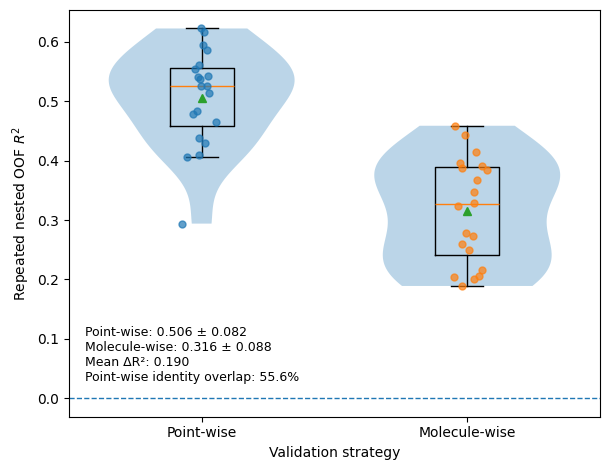

In [ ]:
point = repeat_results.loc[repeat_results.protocol=="Point-wise", "R2"].to_numpy()
group = repeat_results.loc[repeat_results.protocol=="Molecule-wise", "R2"].to_numpy()
mean_overlap = repeat_results.loc[
    repeat_results.protocol=="Point-wise", "point_overlap_fraction"
].mean()

fig, ax = plt.subplots(figsize=(6.2, 4.8))

data = [point, group]
positions = [1, 2]

ax.violinplot(
    data, positions=positions, widths=0.70,
    showmeans=False, showmedians=False, showextrema=False
)
ax.boxplot(
    data, positions=positions, widths=0.24,
    showmeans=True, showfliers=False
)

rng = np.random.default_rng(2026)
for xpos, vals in zip(positions, data):
    jitter = rng.normal(0, 0.04, len(vals))
    ax.scatter(np.full(len(vals), xpos)+jitter, vals, s=25, alpha=0.70, zorder=3)

ax.axhline(0, linestyle="--", linewidth=1.0)
ax.set_xticks(positions)
ax.set_xticklabels(["Point-wise", "Molecule-wise"])
ax.set_ylabel(r"Repeated nested OOF $R^2$")
ax.set_xlabel("Validation strategy")

annotation = (
    f"Point-wise: {point.mean():.3f} ± {point.std(ddof=1):.3f}\n"
    f"Molecule-wise: {group.mean():.3f} ± {group.std(ddof=1):.3f}\n"
    f"Mean ΔR²: {delta_r2.mean():.3f}\n"
    f"Point-wise identity overlap: {100*mean_overlap:.1f}%"
)
ax.text(
    0.03, 0.08, annotation,
    transform=ax.transAxes,
    va="bottom", ha="left", fontsize=9,
    bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.85, edgecolor="none")
)

fig.tight_layout()
fig.savefig("Figure1_repeated_nested_OOF_R2.svg", bbox_inches="tight")
fig.savefig("Figure1_repeated_nested_OOF_R2.pdf", bbox_inches="tight")
fig.savefig("Figure1_repeated_nested_OOF_R2.png", dpi=600, bbox_inches="tight")
plt.show()


## 9. Figure S1

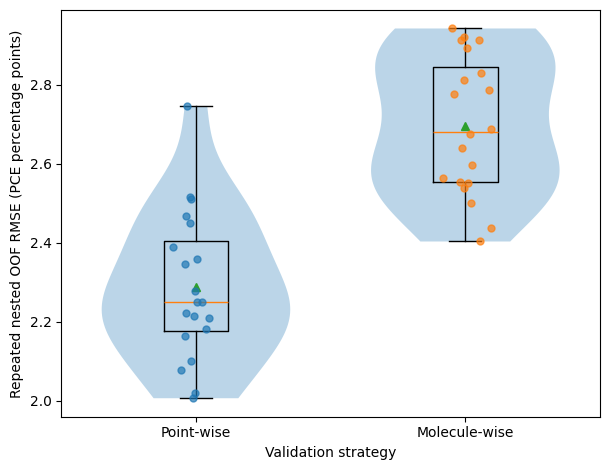

In [ ]:
point_rmse = repeat_results.loc[repeat_results.protocol=="Point-wise", "RMSE"].to_numpy()
group_rmse = repeat_results.loc[repeat_results.protocol=="Molecule-wise", "RMSE"].to_numpy()

fig, ax = plt.subplots(figsize=(6.2, 4.8))
data = [point_rmse, group_rmse]

ax.violinplot(data, positions=[1,2], widths=0.70,
              showmeans=False, showmedians=False, showextrema=False)
ax.boxplot(data, positions=[1,2], widths=0.24,
           showmeans=True, showfliers=False)

rng = np.random.default_rng(2027)
for xpos, vals in zip([1,2], data):
    jitter = rng.normal(0, 0.04, len(vals))
    ax.scatter(np.full(len(vals), xpos)+jitter, vals, s=25, alpha=0.70, zorder=3)

ax.set_xticks([1,2])
ax.set_xticklabels(["Point-wise", "Molecule-wise"])
ax.set_ylabel("Repeated nested OOF RMSE (PCE percentage points)")
ax.set_xlabel("Validation strategy")
fig.tight_layout()

fig.savefig("FigureS_repeated_nested_OOF_RMSE.svg", bbox_inches="tight")
fig.savefig("FigureS_repeated_nested_OOF_RMSE.pdf", bbox_inches="tight")
fig.savefig("FigureS_repeated_nested_OOF_RMSE.png", dpi=600, bbox_inches="tight")
plt.show()


## 10. Save the full audit trail


In [ ]:
repeat_results.to_csv("Figure1_repeat_level_metrics.csv", index=False)
fold_results.to_csv("Figure1_outer_fold_audit.csv", index=False)
oof_predictions.to_csv("Figure1_all_OOF_predictions.csv", index=False)

settings = {
    "data_file": DATA_FILE,
    "sha256": sha256sum(DATA_FILE),
    "shape": list(df.shape),
    "n_predictors": int(X.shape[1]),
    "n_unique_smiles": int(groups.nunique()),
    "run_mode": RUN_MODE,
    "n_repeats": N_REPEATS,
    "outer_folds": OUTER_FOLDS,
    "inner_folds": INNER_FOLDS,
    "n_iter": N_ITER,
    "repeat_seeds": REPEAT_SEEDS,
    "model_seed": MODEL_SEED,
    "search_seed": SEARCH_SEED,
    "xgboost": xgb.__version__,
    "sklearn": sklearn.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "param_distributions": PARAM_DISTRIBUTIONS,
    "mean_delta_R2": float(delta_r2.mean()),
    "partition_resampling_delta_R2_interval": [float(ci[0]), float(ci[1])],
    "mean_point_identity_overlap_fraction": float(mean_overlap),
}

with open("Figure1_settings.json", "w", encoding="utf-8") as f:
    json.dump(settings, f, indent=2, ensure_ascii=False)

files_to_zip = [
    "Figure1_repeated_nested_OOF_R2.svg",
    "Figure1_repeated_nested_OOF_R2.pdf",
    "Figure1_repeated_nested_OOF_R2.png",
    "FigureS_repeated_nested_OOF_RMSE.svg",
    "FigureS_repeated_nested_OOF_RMSE.pdf",
    "FigureS_repeated_nested_OOF_RMSE.png",
    "Figure1_repeat_level_metrics.csv",
    "Figure1_outer_fold_audit.csv",
    "Figure1_all_OOF_predictions.csv",
    "Figure1_settings.json",
]

with zipfile.ZipFile("Figure1_repeated_nested_OOF_outputs.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for fn in files_to_zip:
        z.write(fn)

print("Created Figure1_repeated_nested_OOF_outputs.zip")


Created Figure1_repeated_nested_OOF_outputs.zip


In [ ]:
from google.colab import files
files.download("Figure1_repeated_nested_OOF_outputs.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>